In [1]:
import pandas as pd

df = pd.read_csv("../data/salesdaily.csv")
df.head()

,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,1/2/2014,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0,2014,1,248,Thursday
1,1/3/2014,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0,2014,1,276,Friday
2,1/4/2014,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0,2014,1,276,Saturday
3,1/5/2014,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0,2014,1,276,Sunday
4,1/6/2014,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0,2014,1,276,Monday


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2106 entries, 0 to 2105
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   datum         2106 non-null   str    
 1   M01AB         2106 non-null   float64
 2   M01AE         2106 non-null   float64
 3   N02BA         2106 non-null   float64
 4   N02BE         2106 non-null   float64
 5   N05B          2106 non-null   float64
 6   N05C          2106 non-null   float64
 7   R03           2106 non-null   float64
 8   R06           2106 non-null   float64
 9   Year          2106 non-null   int64  
 10  Month         2106 non-null   int64  
 11  Hour          2106 non-null   int64  
 12  Weekday Name  2106 non-null   str    
dtypes: float64(8), int64(3), str(2)
memory usage: 214.0 KB


In [3]:
df.isna().sum()

datum           0
M01AB           0
M01AE           0
N02BA           0
N02BE           0
N05B            0
N05C            0
R03             0
R06             0
Year            0
Month           0
Hour            0
Weekday Name    0
dtype: int64

In [4]:
df.describe()

,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour
count,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000
mean,5.033683,3.895830,3.880441,29.917095,8.853627,0.593522,5.512262,2.900198,2016.401235,6.344255,275.945869
std,2.737579,2.133337,2.384010,15.590966,5.605605,1.092988,6.428736,2.415816,1.665060,3.386954,1.970547
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2014.000000,1.000000,190.000000
25%,3.000000,2.340000,2.000000,19.000000,5.000000,0.000000,1.000000,1.000000,2015.000000,3.000000,276.000000
50%,4.990000,3.670000,3.500000,26.900000,8.000000,0.000000,4.000000,2.000000,2016.000000,6.000000,276.000000
75%,6.670000,5.138000,5.200000,38.300000,12.000000,1.000000,8.000000,4.000000,2018.000000,9.000000,276.000000
max,17.340000,14.463000,16.000000,161.000000,54.833333,9.000000,45.000000,15.000000,2019.000000,12.000000,276.000000


In [5]:
df["datum"] = pd.to_datetime(df["datum"], format="%m/%d/%Y")
df = df.sort_values("datum").reset_index(drop=True)
df["datum"].min(), df["datum"].max()

(Timestamp('2014-01-02 00:00:00'), Timestamp('2019-10-08 00:00:00'))

In [6]:
full_range = pd.date_range(df["datum"].min(), df["datum"].max(), freq="D")
len(full_range), len(df), df["datum"].duplicated().sum()

(2106, 2106, np.int64(0))

In [7]:
(df.loc[:, "M01AB":"R06"] == 0).mean().round(2)

M01AB    0.02
M01AE    0.02
N02BA    0.04
N02BE    0.01
N05B     0.02
N05C     0.68
R03      0.23
R06      0.12
dtype: float64

Matplotlib is building the font cache; this may take a moment.


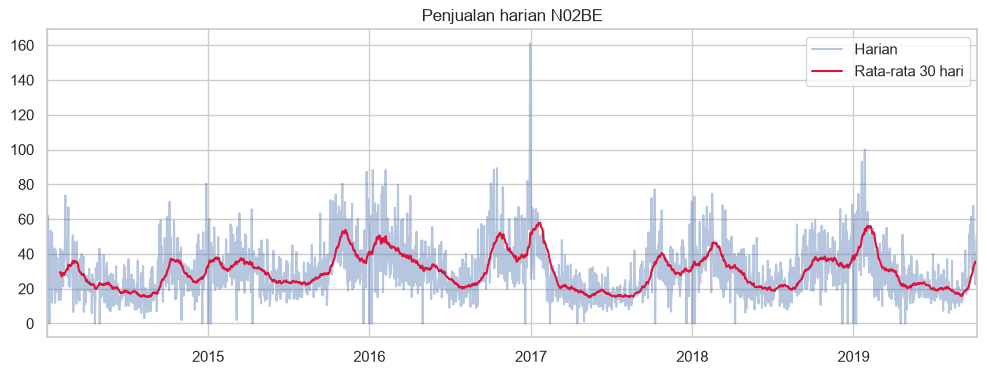

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

target = "N02BE"
ts = df.set_index("datum")[target]

fig, ax = plt.subplots(figsize=(12, 4))
ts.plot(ax=ax, alpha=0.4, label="Harian")
ts.rolling(30).mean().plot(ax=ax, color="crimson", label="Rata-rata 30 hari")
ax.set_title(f"Penjualan harian {target}")
ax.set_xlabel("")
ax.legend()
plt.show()

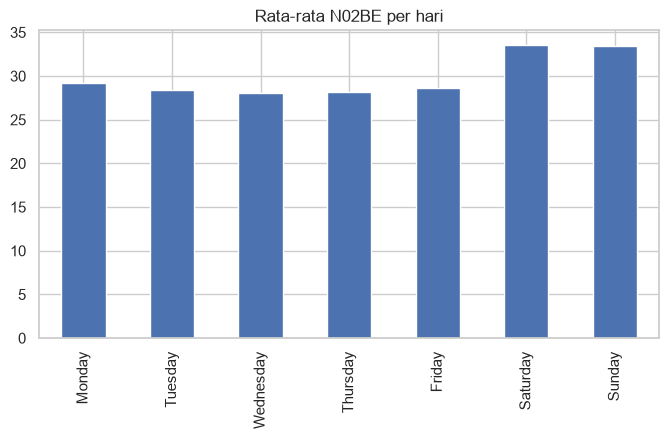

In [9]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

(df.groupby("Weekday Name")[target].mean()
   .reindex(order)
   .plot(kind="bar", figsize=(8, 4), title=f"Rata-rata {target} per hari"))
plt.xlabel("")
plt.show()

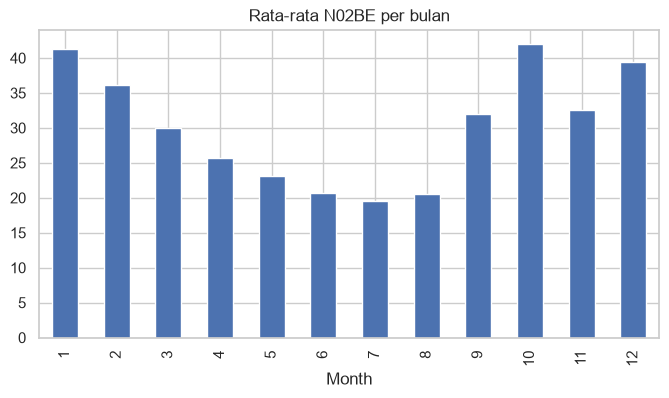

In [10]:
(df.groupby("Month")[target].mean()
   .plot(kind="bar", figsize=(8, 4), title=f"Rata-rata {target} per bulan"))
plt.show()

In [11]:
print(df.groupby("Year")[target].mean().round(1))
df["Hour"].value_counts().head()

Year
2014    25.5
2015    32.7
2016    36.4
2017    25.4
2018    30.8
2019    28.4
Name: N02BE, dtype: float64


Hour
276    2104
248       1
190       1
Name: count, dtype: int64

In [12]:
df.loc[df[target] == 0, "datum"].dt.strftime("%Y-%m-%d").tolist()

['2014-01-07',
 '2014-04-20',
 '2014-05-01',
 '2014-12-19',
 '2015-01-01',
 '2015-01-07',
 '2015-04-12',
 '2015-12-19',
 '2016-01-01',
 '2016-01-07',
 '2016-05-01',
 '2016-12-19',
 '2017-02-13',
 '2017-04-16',
 '2017-10-09',
 '2017-12-19',
 '2018-01-01',
 '2018-01-07',
 '2018-04-08',
 '2018-12-06',
 '2018-12-08',
 '2018-12-19',
 '2019-01-01',
 '2019-01-07',
 '2019-04-18',
 '2019-04-28']

In [13]:
df.nlargest(5, target)[["datum", target]]

,datum,N02BE
1093,2016-12-30,161.00
1094,2016-12-31,108.70
1851,2019-01-27,100.10
1850,2019-01-26,97.80
1844,2019-01-20,93.05


In [14]:
df["libur_tetap"] = (
    ((df["datum"].dt.month == 1) & (df["datum"].dt.day.isin([1, 7]))) |
    ((df["datum"].dt.month == 12) & (df["datum"].dt.day == 19))
).astype(int)

df.loc[df["libur_tetap"] == 1, ["datum", target]]

,datum,N02BE
5,2014-01-07,0.000
351,2014-12-19,0.000
364,2015-01-01,0.000
370,2015-01-07,0.000
716,2015-12-19,0.000
729,2016-01-01,0.000
735,2016-01-07,0.000
1082,2016-12-19,0.000
1095,2017-01-01,25.675
1101,2017-01-07,34.625


In [17]:
data = df[["datum", target, "libur_tetap"]].copy()

data["lag_1"] = data[target].shift(1)
data["lag_7"] = data[target].shift(7)
data["rata_7"] = data[target].shift(1).rolling(7).mean()
data["rata_30"] = data[target].shift(1).rolling(30).mean()

data["hari"] = data["datum"].dt.day_of_week
data["bulan"] = data["datum"].dt.month
data["akhir_pekan"] = (data["hari"] >= 5).astype(int)

data = data.dropna().reset_index(drop=True)
data.shape

(2076, 10)

In [18]:
train = data[data["datum"] < "2019-01-01"]
test = data[data["datum"] >= "2019-01-01"]
len(train), len(test)

(1795, 281)

In [19]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

y_test = test[target]

baseline = {
    "Naive (kemarin)": test["lag_1"],
    "Naive (minggu lalu)": test["lag_7"],
    "Rata-rata 7 hari": test["rata_7"],
    "Rata-rata 30 hari": test["rata_30"],
}

hasil = pd.DataFrame({
    nama: {
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": root_mean_squared_error(y_test, pred),
    }
    for nama, pred in baseline.items()
}).T.round(2)

hasil

,MAE,RMSE
Naive (kemarin),11.35,15.10
Naive (minggu lalu),10.90,14.88
Rata-rata 7 hari,9.07,12.26
Rata-rata 30 hari,9.84,13.43


In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

fitur_num = ["lag_1", "lag_7", "rata_7", "rata_30", "libur_tetap", "akhir_pekan"]
fitur_kat = ["hari", "bulan"]
fitur = fitur_num + fitur_kat

X_train, y_train = train[fitur], train[target]
X_test = test[fitur]


def buat_pipeline(model):
    prep = ColumnTransformer(
        [("kat", OneHotEncoder(handle_unknown="ignore"), fitur_kat)],
        remainder="passthrough",
    )
    return Pipeline([("prep", prep), ("model", model)])


models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
}

hasil_model = {}
for nama, model in models.items():
    pipe = buat_pipeline(model)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    hasil_model[nama] = {
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": root_mean_squared_error(y_test, pred),
    }

pd.concat([hasil, pd.DataFrame(hasil_model).T.round(2)])

,MAE,RMSE
Naive (kemarin),11.35,15.10
Naive (minggu lalu),10.90,14.88
Rata-rata 7 hari,9.07,12.26
Rata-rata 30 hari,9.84,13.43
Linear Regression,8.45,11.01
Random Forest,8.82,11.50


In [21]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)
X_all, y_all = data[fitur], data[target]

rows = []
for i, (tr, te) in enumerate(tscv.split(X_all), start=1):
    y_te = y_all.iloc[te]
    row = {"fold": i, "Rata-rata 7 hari": mean_absolute_error(y_te, data["rata_7"].iloc[te])}
    for nama, model in models.items():
        pipe = buat_pipeline(model)
        pipe.fit(X_all.iloc[tr], y_all.iloc[tr])
        row[nama] = mean_absolute_error(y_te, pipe.predict(X_all.iloc[te]))
    rows.append(row)

cv = pd.DataFrame(rows).set_index("fold")
cv.loc["rata-rata"] = cv.mean()
cv.round(2)

,Rata-rata 7 hari,Linear Regression,Random Forest
fold,,,
1,9.08,9.47,9.66
2,11.13,10.48,11.16
3,8.41,8.26,8.83
4,9.26,8.83,9.22
5,9.51,8.67,9.06
rata-rata,9.48,9.14,9.59


In [22]:
pipe_lr = buat_pipeline(LinearRegression()).fit(X_train, y_train)

cek = test[["datum", target]].copy()
cek["pred"] = pipe_lr.predict(X_test)
cek["abs_err"] = (cek[target] - cek["pred"]).abs()
cek["hari_nol"] = cek[target] == 0

print(cek.groupby("hari_nol")["abs_err"].agg(["count", "mean"]).round(2))
cek.nlargest(5, "abs_err").round(2)

          count   mean
hari_nol              
False       277   8.39
True          4  12.75


/var/folders/0d/38nk53q148l6vk5n5gw045sc0000gn/T/ipykernel_77913/2539787428.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  cek.nlargest(5, "abs_err").round(2)


,datum,N02BE,pred,abs_err,hari_nol
1814,2019-01-20,93.05,55.19,37.86,False
1820,2019-01-26,97.80,60.86,36.94,False
1821,2019-01-27,100.10,66.00,34.10,False
1906,2019-04-22,51.00,18.20,32.80,False
1842,2019-02-17,15.16,44.27,29.11,False


In [23]:
def buat_fitur(df_in, ekstra=False):
    d = df_in[["datum", target, "libur_tetap"]].copy()
    d["lag_1"] = d[target].shift(1)
    d["lag_7"] = d[target].shift(7)
    d["rata_7"] = d[target].shift(1).rolling(7).mean()
    d["rata_30"] = d[target].shift(1).rolling(30).mean()
    if ekstra:
        d["lag_2"] = d[target].shift(2)
        d["lag_3"] = d[target].shift(3)
        d["rata_3"] = d[target].shift(1).rolling(3).mean()
    d["hari"] = d["datum"].dt.day_of_week
    d["bulan"] = d["datum"].dt.month
    d["akhir_pekan"] = (d["hari"] >= 5).astype(int)
    return d.dropna().reset_index(drop=True)


def cv_mae(d, fitur_num):
    fitur_pakai = fitur_num + fitur_kat
    X, y = d[fitur_pakai], d[target]
    maes = []
    for tr, te in TimeSeriesSplit(n_splits=5).split(X):
        pipe = buat_pipeline(LinearRegression()).fit(X.iloc[tr], y.iloc[tr])
        maes.append(mean_absolute_error(y.iloc[te], pipe.predict(X.iloc[te])))
    return [round(m, 2) for m in maes], round(sum(maes) / len(maes), 2)


awal = ["lag_1", "lag_7", "rata_7", "rata_30", "libur_tetap", "akhir_pekan"]
tambahan = awal + ["lag_2", "lag_3", "rata_3"]

print("Fitur awal :", cv_mae(buat_fitur(df), awal))
print("Fitur +3   :", cv_mae(buat_fitur(df, ekstra=True), tambahan))

Fitur awal : ([9.47, 10.48, 8.26, 8.83, 8.67], 9.14)
Fitur +3   : ([9.64, 10.5, 8.26, 8.83, 8.68], 9.18)


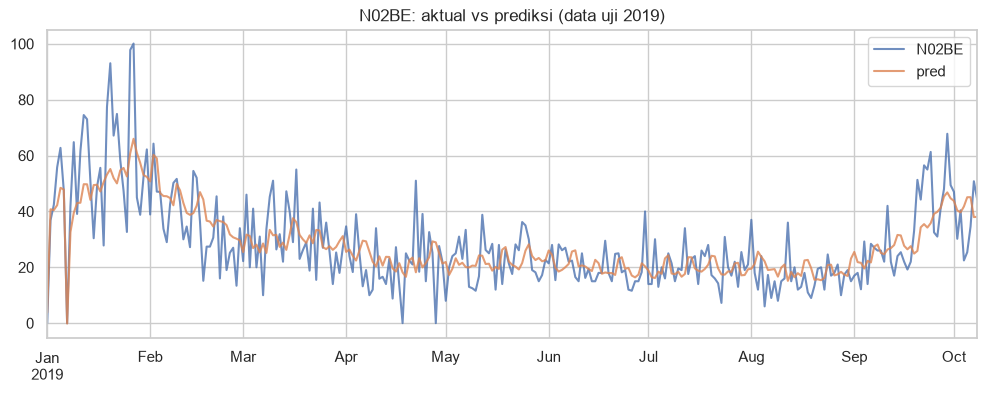

In [24]:
fig, ax = plt.subplots(figsize=(12, 4))
cek.set_index("datum")[[target, "pred"]].plot(ax=ax, alpha=0.8)
ax.set_title(f"{target}: aktual vs prediksi (data uji 2019)")
ax.set_xlabel("")
plt.show()

In [25]:
prep = pipe_lr.named_steps["prep"]
koef = pd.Series(
    pipe_lr.named_steps["model"].coef_,
    index=prep.get_feature_names_out(),
)
koef.sort_values(key=abs, ascending=False).round(2).head(10)

remainder__libur_tetap   -41.57
kat__bulan_12              6.46
kat__bulan_7              -2.92
kat__bulan_6              -2.86
kat__bulan_9               2.79
kat__bulan_10              2.71
remainder__akhir_pekan     2.64
kat__bulan_1               2.52
kat__bulan_5              -2.37
kat__bulan_11             -1.87
dtype: float64

In [26]:
import joblib
from pathlib import Path

Path("../models").mkdir(exist_ok=True)

model_final = buat_pipeline(LinearRegression()).fit(data[fitur], data[target])
joblib.dump(model_final, "../models/model_n02be.joblib")

['../models/model_n02be.joblib']